[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xylem-lab/GEO-ANOM-dashboard/blob/task1/final-2026-11-03/notebooks/12_task1_validation.ipynb)

# 12 — Task 1 validation: does the mapped roof hold the birds Maryland reports? And why we stop here

**Question.** Notebook 11 checked the map against the USGS tracing (are the outlines on real houses?). Here the check is independent of any tracing: converting the mapped roof area into birds, do we get the numbers that farmers, the state and the industry report?

**How.** Roof area → floor area → birds a house holds at once (stocking density) → birds on a given day (share of days with a flock) → birds a year (flocks a year). Each assumption has a low / mid / high value, so the map gives a **range**, compared with:

| source | what it counts | year |
|---|---|---|
| MDE AFO/CAFO permits (Maryland Open Data) | permitted birds per farm (capacity) | active permits, 2026 snapshot |
| USDA Census of Agriculture (via the Maryland Animal Waste Technology report, Lansing et al. 2023) | broilers on hand, by county | 2017 |
| MDE CAFO data (same report) | broilers by county | 2017 |
| Delmarva Chicken Association | birds and houses on Delmarva | 2024 |

| assumption | low | mid | high | basis |
|---|---|---|---|---|
| floor / roof footprint | 0.90 | 0.93 | 0.96 | eaves overhang |
| birds per ft² of floor at placement | 0.90 | 1.10 | 1.30 | NCC guidelines 6.5–9 lb/ft² at market weight; Delmarva birds ~6–7.3 lb |
| share of days with birds | 0.70 | 0.80 | 0.90 | 5–6 flocks a year, 2–3 weeks between flocks |
| flocks a year | 5.0 | 5.5 | 6.0 | Delmarva practice |

The year gap matters (map: 2023 photos; Census: 2017; houses are built and closed every year), so agreement is judged on ranges and on the pattern across counties, not on one number.

In [1]:
# ── Setup: the same cell works in Google Colab and locally ──────────────────────
import os, sys, json, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
CODE_VERSION = "task1/final-2026-11-03"   # branch, tag or commit to run; the exact commit is recorded in run_meta.json

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # results go to the shared drive's Task1_results
    ROOT = Path("/content/GEO-ANOM-dashboard")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/xylem-lab/GEO-ANOM-dashboard", str(ROOT)], check=True)
    # always bring the copy up to date (a reused Colab session keeps an old copy)
    head = lambda: subprocess.run(["git", "-C", str(ROOT), "rev-parse", "HEAD"], capture_output=True, text=True).stdout
    before = head()
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin"], check=True)
    remote = f"origin/{CODE_VERSION}"
    target = remote if subprocess.run(["git", "-C", str(ROOT), "rev-parse", "-q", "--verify", remote],
                                      capture_output=True).returncode == 0 else CODE_VERSION
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "--detach", target], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-colab.txt")], check=True)
    if head() != before and "geo_anom" in sys.modules:   # new code, but the old version is already loaded
        raise RuntimeError("Code updated. Runtime -> Restart session, then Run all again.")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
# reload edited geo_anom/ code automatically, without restarting the kernel
if "google.colab" not in sys.modules:   # Colab's IPython can't load autoreload on Python 3.12+ (no `imp`)
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)

from geo_anom.task1 import env, region
from geo_anom.task1 import county as C
from geo_anom.task1 import final as FN
from geo_anom.task1 import training as T
from scipy import stats
from geo_anom.task1.pipeline import git_commit
print("running in", "Colab" if IN_COLAB else "local", "| results ->", env.results_root())

running in local | results -> /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task1_results


## Settings

In [2]:
RELEASE = FN.final_dir() / "release_v1"          # notebook 11's frozen map
AWTF = ROOT / "data/reference/awtf_2017_broiler_layer_inventory_by_county.csv"
REGISTRY = ROOT / "data/reference/mde_afo_registry_snapshot.json"
A = FN.ASSUMPTIONS
final = gpd.read_file(RELEASE / "maryland_poultry_houses.geojson")
lad = pd.read_csv(RELEASE / "ladder.csv")
awtf = pd.read_csv(AWTF, comment="#").set_index("county").rename(index={"Saint Mary's": "St. Mary's"})
reg = pd.DataFrame(json.load(open(REGISTRY))["sites"])
permits = reg[reg.animal_type == "chickens_not_laying_hens"].groupby("county").headcount.sum()
print(f"{len(final):,} houses | {len(reg[reg.animal_type == 'chickens_not_laying_hens'])} broiler permits, {permits.sum() / 1e6:.1f} M birds permitted")

2,833 houses | 380 broiler permits, 50.9 M birds permitted


## 1. Capacity: mapped roof vs MDE permitted birds

A permit states how many birds the farm may hold at once, which is what a roof-area estimate gives. Not every farm needs a permit (small ones are below the threshold, which is legal), so permits are expected to sit at or below the mapped capacity.

In [3]:
V = FN.validation_table(final, awtf, permits, A)
M = 1e6
cols = ["houses", "capacity_low", "capacity_mid", "capacity_high", "mde_permitted"]
display((V[cols].assign(**{c: V[c] / M for c in cols[1:]})).round(2).rename(columns=lambda c: c + (" (M)" if c != "houses" else "")))
v = V.drop(index="Total").dropna(subset=["mde_permitted"])
r, p = stats.pearsonr(v.capacity_mid, v.mde_permitted)
t = V.loc["Total"]
print(f"Total: mapped capacity {t.capacity_low / M:.1f}-{t.capacity_high / M:.1f} M (mid {t.capacity_mid / M:.1f}) vs permitted {t.mde_permitted / M:.1f} M "
      f"-> permits = {t.mde_permitted / t.capacity_mid:.0%} of mid | counties: Pearson r = {r:.2f} (n={len(v)})")

,houses,capacity_low (M),capacity_mid (M),capacity_high (M),mde_permitted (M)
county,,,,,
Caroline,517.0,11.42,14.43,17.60,9.63
Carroll,2.0,0.02,0.02,0.03,NaN
Cecil,30.0,0.74,0.93,1.14,0.31
Dorchester,285.0,6.23,7.87,9.61,3.95
Frederick,21.0,0.57,0.71,0.87,0.02
Harford,1.0,0.01,0.01,0.01,NaN
Kent,51.0,1.07,1.35,1.65,1.05
Queen Anne's,220.0,5.35,6.75,8.24,5.16
Somerset,474.0,9.73,12.29,14.99,8.17


Total: mapped capacity 60.8-93.7 M (mid 76.8) vs permitted 50.9 M -> permits = 66% of mid | counties: Pearson r = 0.99 (n=10)


## 2. Birds on hand: mapped roof vs Census of Agriculture 2017 and MDE CAFO 2017

,houses,on_hand_low,on_hand_mid,on_hand_high,census2017_on_hand,mde_cafo2017_on_hand
county,,,,,,
Caroline,517.0,8.00,11.54,15.84,11.42,13.40
Carroll,2.0,0.01,0.02,0.03,0.00,0.45
Cecil,30.0,0.52,0.75,1.02,NaN,2.65
Dorchester,285.0,4.36,6.30,8.65,5.00,5.10
Frederick,21.0,0.40,0.57,0.78,0.07,NaN
Harford,1.0,0.01,0.01,0.01,0.03,NaN
Kent,51.0,0.75,1.08,1.49,1.02,2.76
Queen Anne's,220.0,3.74,5.40,7.41,4.61,5.08
Somerset,474.0,6.81,9.83,13.49,12.45,10.11


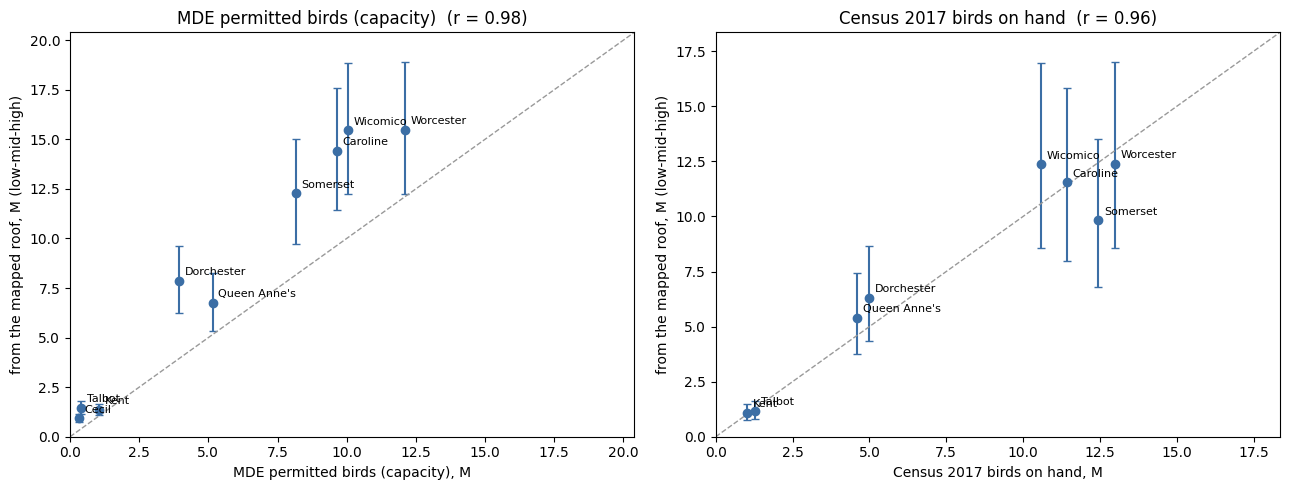

In [4]:
cols = ["on_hand_low", "on_hand_mid", "on_hand_high", "census2017_on_hand", "mde_cafo2017_on_hand"]
display((V[["houses"] + cols].assign(**{c: V[c] / M for c in cols})).round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (ref, name) in zip(ax, [("mde_permitted", "MDE permitted birds (capacity)"), ("census2017_on_hand", "Census 2017 birds on hand")]):
    lo, mid, hi = (("capacity_low", "capacity_mid", "capacity_high") if ref == "mde_permitted" else ("on_hand_low", "on_hand_mid", "on_hand_high"))
    d = V.drop(index="Total").dropna(subset=[ref]); d = d[d[ref] > 1e5]
    a.errorbar(d[ref] / M, d[mid] / M, yerr=[(d[mid] - d[lo]) / M, (d[hi] - d[mid]) / M], fmt="o", color="#3b6ea5", capsize=3)
    for n, row in d.iterrows(): a.annotate(n, (row[ref] / M, row[mid] / M), fontsize=8, xytext=(4, 4), textcoords="offset points")
    m = max(d[ref].max(), d[hi].max()) / M * 1.08
    a.plot([0, m], [0, m], color="0.6", ls="--", lw=1); a.set_xlim(0, m); a.set_ylim(0, m)
    rr, _ = stats.pearsonr(d[ref], d[mid])
    a.set_xlabel(name + ", M"); a.set_ylabel("from the mapped roof, M (low-mid-high)"); a.set_title(f"{name}  (r = {rr:.2f})")
plt.tight_layout(); plt.show()

## 3. Per house and per year vs the Delmarva Chicken Association

In [5]:
ft2 = final.roof_m2 * FN.FT2_PER_M2
per_house = {k: ft2.mean() * A["floor_share"][i] * A["birds_per_ft2"][i] for i, k in enumerate(["low", "mid", "high"])}
per_year = {k: per_house[k] * A["flocks_per_year"][i] for i, k in enumerate(["low", "mid", "high"])}
dca = FN.DCA_2024["birds"] / FN.DCA_2024["houses"]
es = final[final.source != "checked by eye (west of the Bay)"]
print(f"average mapped house: {ft2.mean():,.0f} ft2 roof -> {per_house['low']:,.0f}-{per_house['high']:,.0f} birds a flock (mid {per_house['mid']:,.0f})")
print(f"birds a house a year: {per_year['low'] / 1e3:,.0f}k-{per_year['high'] / 1e3:,.0f}k (mid {per_year['mid'] / 1e3:,.0f}k) | DCA 2024 average: {dca / 1e3:,.0f}k")
print(f"Eastern Shore birds a year: mapped roof {per_year['low'] * len(es) / M:,.0f}-{per_year['high'] * len(es) / M:,.0f} M | "
      f"{len(es):,} houses x DCA average = {len(es) * dca / M:,.0f} M")
print(f"Maryland's mapped houses = {len(es) / FN.DCA_2024['houses']:.0%} of DCA's {FN.DCA_2024['houses']:,} Delmarva houses")

average mapped house: 26,514 ft2 roof -> 21,476-33,089 birds a flock (mid 27,124)
birds a house a year: 107k-199k (mid 149k) | DCA 2024 average: 122k
Eastern Shore birds a year: mapped roof 301-557 M | 2,807 houses x DCA average = 344 M
Maryland's mapped houses = 57% of DCA's 4,909 Delmarva houses


## 4. Is the map good enough for Task 2?

Task 2 turns houses into litter and nutrients and compares them with what the cropland needs. Two questions decide whether more map work would change its answers:

1. **Does the county pattern still move?** If the ranking of counties stopped changing several steps ago, more houses found won't reorder the surplus map.
2. **How big is the remaining map error next to the Task 2 coefficient spread?** If the litter and nutrient coefficients are uncertain by more than the map, a better map doesn't narrow the Task 2 answer.

In [6]:
c = lad[lad.county != "Eastern Shore"].pivot(index="county", columns="step", values="houses")[FN.STEPS]
rho = {s: stats.spearmanr(c["published model"], c[s])[0] for s in FN.STEPS}
rho_final = {s: stats.spearmanr(c[s], c["checked by eye"])[0] for s in FN.STEPS}
display(pd.DataFrame({"houses": c.sum(), "rank vs published model (Spearman)": rho, "rank vs final (Spearman)": rho_final}).round(3))
e = lad[(lad.county == "Eastern Shore") & (lad.step == "checked by eye")].iloc[0]
missed = 1 - e.recall                               # traced houses with no outline (some were torn down since 2016/17: a ceiling)
extra = 1 - e.precision_checked                     # outlines not on a traced or confirmed house (some are new houses: a ceiling)
budget = pd.DataFrame([
    ["map: houses missed (1 - recall)", f"up to {missed:.0%} fewer houses than real"],
    ["map: outlines not confirmed (1 - precision, checked)", f"up to {extra:.0%} more"],
    ["litter per bird (Bay Program formula vs UD vs new 2026 Delmarva study)", "2.3-3.0 lb: about +/-13%"],
    ["first-year N available from litter", "31-70%: a factor of 2"],
    ["N / P per ton of litter (DE/MD records; P fell ~16% 1995-2013)", "about +/-15-20%"],
    ["birds per house (stocking density, flocks a year; this notebook)", f"{per_year['low'] / per_year['mid'] - 1:+.0%} / {per_year['high'] / per_year['mid'] - 1:+.0%}"],
], columns=["source of uncertainty", "size"])
display(budget)

,houses,rank vs published model (Spearman),rank vs final (Spearman)
published model,2329,1.00,0.95
rectangle outlines,2329,1.00,0.95
brightened photo,2628,0.95,1.00
SAM repair,2823,0.95,1.00
checked by eye,2807,0.95,1.00


,source of uncertainty,size
0,map: houses missed (1 - recall),up to 20% fewer houses than real
1,"map: outlines not confirmed (1 - precision, ch...",up to 3% more
2,litter per bird (Bay Program formula vs UD vs ...,2.3-3.0 lb: about +/-13%
3,first-year N available from litter,31-70%: a factor of 2
4,N / P per ton of litter (DE/MD records; P fell...,about +/-15-20%
5,"birds per house (stocking density, flocks a ye...",-28% / +33%


## 5. Save

In [7]:
V.to_csv(RELEASE / "validation.csv")
man = json.loads((RELEASE / "MANIFEST.json").read_text())
man["files"]["validation.csv"] = env.sha256(RELEASE / "validation.csv")
man["validation"] = {"notebook": "12_task1_validation", "git_commit": git_commit(), "assumptions": A, "dca_2024": FN.DCA_2024,
                     "sources": {"permits": "MDE AFO/CAFO registry snapshot (data/reference)", "census_2017": str(AWTF.name)}}
(RELEASE / "MANIFEST.json").write_text(json.dumps(man, indent=2, default=str))
print("saved", RELEASE / "validation.csv")

saved /Users/umeshadari/Library/CloudStorage/GoogleDrive-umeshka@umd.edu/Shared drives/AIM-GEO-ANOM/Task1_results/final/release_v1/validation.csv


## Why Task 1 stops here

**1. The map's roof holds the birds Maryland reports.**
- Birds on hand: the map gives **42.6–84.4 M (mid 61.5 M)**; the 2017 Census of Agriculture counted **59.5 M** and MDE's 2017 CAFO data **69.2 M**. Every county's Census number falls inside the map's range (8 of 8); across counties r = 0.96 (Census) and 0.98 (MDE 2017).
- Capacity: MDE permits cover **50.9 M** birds vs **60.8–93.7 M** the mapped roof can hold; across counties r = 0.99. Permits are below the mapped capacity in every county, as expected: farms below the CAFO threshold don't need one (legal), and idle houses still have roofs. That gap is the starting point for active vs idle houses in Task 2.
- Per house a year: **107k–199k birds (mid 149k)** from the roof vs **122k** DCA's 2024 Delmarva average — inside the range. 2,807 Eastern Shore houses × the DCA average = 344 M birds a year.

**2. The county pattern stopped moving.** The ranking of counties by houses is the same from step 2 on (Spearman 1.00 against the final map; 0.95 even for the published model alone). More houses found would not reorder the surplus map Task 2 draws.

**3. The remaining map error is smaller than the Task 2 coefficient spread.** At most ~20% of houses missed (a ceiling: some traced houses were torn down since 2016/17) and ~3% of outlines unconfirmed, against: first-year litter N availability 31–70% (a factor of 2), birds per house −28% / +33%, N and P per ton ±15–20%, litter per bird ±13%. A better map would not narrow Task 2's answer; better coefficients would.

**4. The next gains would need new data, not new methods.** The missed houses are mostly on the darkest 2023 flights with no usable candidate at all; the two expensive methods tried (fine-tuning, road rule) did not beat the current map. The cheap way to more houses is the next NAIP flight, not more model work.

**So Task 1 closes with:** 2,833 houses, 6.98 km² of roof, recall 0.805 and precision 0.97 (checked by eye) on the Eastern Shore, reproducible from the notebooks, validated against three independent bird counts. Frozen in `Task1_results/final/release_v1/` with checksums.

**Caveats to state in the paper:** Census and MDE inventories are 2017, the map 2023; stocking density and occupancy are literature ranges, not measured; the 26 western houses hold far more birds by roof than Frederick's Census count (0.57 M vs 0.07 M), so they are likely another kind of poultry or idle — flagged, to keep out of Task 2's broiler numbers; Maryland's 2,807 Eastern Shore houses are 57% of DCA's 4,909 Delmarva houses, to be checked against DCA's state split.